In [45]:
import pandas as pd
df=pd.read_csv(r"..\data\processed\fraud_cleaned.csv")

In [46]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["isFraud"])
y = df["isFraud"]

In [47]:
X = X.drop(columns=["nameOrig", "nameDest", "isFlaggedFraud"],
           errors="ignore")

In [48]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

In [49]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [50]:
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

print("\nFraud rate:")
print("Train:", y_train.mean() * 100)
print("Validation:", y_val.mean() * 100)
print("Test:", y_test.mean() * 100)

Train: (4453834, 7) (4453834,)
Validation: (954393, 7) (954393,)
Test: (954393, 7) (954393,)

Fraud rate:
Train: 0.1290797995614565
Validation: 0.1290872837499856
Test: 0.1290872837499856


In [51]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
Categorical features: ['type']


In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [53]:
X_train_processed = preprocessor.fit_transform(X_train)

X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

In [54]:
print("Training distribution:")
print(y_train.value_counts())

print("\nTraining percentages:")
print(y_train.value_counts(normalize=True) * 100)

Training distribution:
isFraud
0    4448085
1       5749
Name: count, dtype: int64

Training percentages:
isFraud
0    99.87092
1     0.12908
Name: proportion, dtype: float64


In [55]:
from collections import Counter

class_counts = Counter(y_train)

scale_pos_weight = (
    class_counts[0] / class_counts[1]
)

print("Scale positive weight:", scale_pos_weight)

Scale positive weight: 773.7145590537485


In [56]:
#pip install xgboost

In [57]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

In [58]:
from sklearn.model_selection import train_test_split

X_train_sample, _, y_train_sample, _ = train_test_split(
    X_train,
    y_train,
    train_size=300_000,
    stratify=y_train,
    random_state=42
)

print("Sample shape:", X_train_sample.shape)
print(y_train_sample.value_counts())

Sample shape: (300000, 7)
isFraud
0    299613
1       387
Name: count, dtype: int64


In [59]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

numeric_features = X_train_sample.select_dtypes(
    include="number"
).columns.tolist()

categorical_features = X_train_sample.select_dtypes(
    include=["object", "category"]
).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

In [60]:
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

baseline_model.fit(X_train_sample, y_train_sample)

C:\Users\Ritesh\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [61]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

y_val_pred = baseline_model.predict(X_val)
y_val_prob = baseline_model.predict_proba(X_val)[:, 1]

print(classification_report(y_val, y_val_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print(
    "PR-AUC (Average Precision):",
    average_precision_score(y_val, y_val_prob)
)

              precision    recall  f1-score   support

           0       1.00      0.95      0.97    953161
           1       0.02      0.97      0.05      1232

    accuracy                           0.95    954393
   macro avg       0.51      0.96      0.51    954393
weighted avg       1.00      0.95      0.97    954393

Confusion Matrix:
[[904771  48390]
 [    37   1195]]
PR-AUC (Average Precision): 0.6564124222012359


In [62]:
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

from xgboost import XGBClassifier

# Calculate class imbalance from the training sample
negative_count = (y_train_sample == 0).sum()
positive_count = (y_train_sample == 1).sum()

pos_weight = negative_count / positive_count

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=500
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=12,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", XGBClassifier(
            n_estimators=150,
            max_depth=6,
            learning_rate=0.1,
            scale_pos_weight=pos_weight,
            eval_metric="aucpr",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining: {name}")

    model.fit(X_train_sample, y_train_sample)

    # Score the unchanged validation data
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("PR-AUC", ascending=False)

print(results_df.to_string(index=False))


Training: Logistic Regression


C:\Users\Ritesh\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



Training: Decision Tree

Training: Random Forest

Training: XGBoost
              Model  Precision   Recall       F1   PR-AUC  ROC-AUC
            XGBoost   0.536562 0.917208 0.677052 0.911798 0.997043
      Random Forest   0.918945 0.763799 0.834220 0.849039 0.995772
      Decision Tree   0.127963 0.867695 0.223034 0.712185 0.932879
Logistic Regression   0.024100 0.969968 0.047032 0.656412 0.993488


In [63]:
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

from xgboost import XGBClassifier

# Calculate class imbalance from the training sample
negative_count = (y_train_sample == 0).sum()
positive_count = (y_train_sample == 1).sum()

pos_weight = negative_count / positive_count

models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=500
        ))
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", DecisionTreeClassifier(
            class_weight="balanced",
            max_depth=12,
            random_state=42
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=15,
            class_weight="balanced_subsample",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", XGBClassifier(
            n_estimators=150,
            max_depth=6,
            learning_rate=0.1,
            scale_pos_weight=pos_weight,
            eval_metric="aucpr",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"\nTraining: {name}")

    model.fit(X_train_sample, y_train_sample)

    # Score the unchanged validation data
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val, predictions, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        )
    })

    trained_models[name] = model

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("PR-AUC", ascending=False)

print(results_df.to_string(index=False))


Training: Logistic Regression


C:\Users\Ritesh\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(



Training: Decision Tree

Training: Random Forest

Training: XGBoost
              Model  Precision   Recall       F1   PR-AUC  ROC-AUC
            XGBoost   0.536562 0.917208 0.677052 0.911798 0.997043
      Random Forest   0.918945 0.763799 0.834220 0.849039 0.995772
      Decision Tree   0.127963 0.867695 0.223034 0.712185 0.932879
Logistic Regression   0.024100 0.969968 0.047032 0.656412 0.993488


In [64]:
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [4, 6],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0]
}

In [65]:
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBClassifier

negative_count = (y_train_sample == 0).sum()
positive_count = (y_train_sample == 1).sum()

pos_weight = negative_count / positive_count

xgb = XGBClassifier(
    scale_pos_weight=pos_weight,
    eval_metric="aucpr",
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

search = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param_grid,
    n_iter=8,
    scoring="average_precision",
    cv=3,
    random_state=42,
    n_jobs=1,
    verbose=1
)

# Use the already-preprocessed training sample
X_tuning = preprocessor.fit_transform(X_train_sample)

search.fit(X_tuning, y_train_sample)

print("Best parameters:", search.best_params_)
print("Best cross-validation PR-AUC:", search.best_score_)

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'subsample': 0.8, 'n_estimators': 200, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Best cross-validation PR-AUC: 0.8957570714176639


In [66]:
X_val_tuning = preprocessor.transform(X_val)

best_model = search.best_estimator_

y_val_prob = best_model.predict_proba(X_val_tuning)[:, 1]

In [67]:
from sklearn.metrics import average_precision_score

print(
    "Validation PR-AUC:",
    average_precision_score(y_val, y_val_prob)
)

Validation PR-AUC: 0.91928969161991


In [68]:
y_val_prob = best_model.predict_proba(X_val_tuning)[:, 1]

In [69]:
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70, 0.80, 0.90]

results = []

for threshold in thresholds:
    y_pred = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_val, y_pred, zero_division=0
        ),
        "False Positives": fp,
        "False Negatives": fn,
        "True Positives": tp
    })

threshold_results = pd.DataFrame(results)
print(threshold_results.round(4).to_string(index=False))

 Threshold  Precision  Recall     F1  False Positives  False Negatives  True Positives
       0.1     0.4289  0.9481 0.5906             1555               64            1168
       0.2     0.5405  0.9261 0.6826              970               91            1141
       0.3     0.6113  0.9075 0.7305              711              114            1118
       0.4     0.6722  0.8937 0.7672              537              131            1101
       0.5     0.7185  0.8847 0.7930              427              142            1090
       0.6     0.7667  0.8774 0.8183              329              151            1081
       0.7     0.8127  0.8628 0.8370              245              169            1063
       0.8     0.8604  0.8458 0.8530              169              190            1042
       0.9     0.9073  0.8182 0.8604              103              224            1008


In [70]:
# Example business constraint — adjust based on requirements
eligible = threshold_results[
    threshold_results["Precision"] >= 0.50
]

if not eligible.empty:
    selected_row = eligible.sort_values(
        "Recall", ascending=False
    ).iloc[0]

    best_threshold = selected_row["Threshold"]
    print("Selected threshold:", best_threshold)
    print(selected_row)
else:
    print("No threshold met the precision requirement.")

Selected threshold: 0.2
Threshold             0.200000
Precision             0.540502
Recall                0.926136
F1                    0.682620
False Positives     970.000000
False Negatives      91.000000
True Positives     1141.000000
Name: 1, dtype: float64


In [71]:
threshold_config = {
    "threshold": float(best_threshold),
    "selection_metric": "recall_subject_to_precision_constraint"
}

In [72]:
X_test_tuning = preprocessor.transform(X_test)

In [73]:
y_test_prob = best_model.predict_proba(X_test_tuning)[:, 1]

y_test_pred = (
    y_test_prob >= best_threshold
).astype(int)

In [74]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Classification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))

print("PR-AUC:", average_precision_score(
    y_test, y_test_prob
))

print("ROC-AUC:", roc_auc_score(
    y_test, y_test_prob
))

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    953161
       Fraud       0.55      0.92      0.69      1232

    accuracy                           1.00    954393
   macro avg       0.77      0.96      0.84    954393
weighted avg       1.00      1.00      1.00    954393

PR-AUC: 0.9144555565846012
ROC-AUC: 0.9964881300902314


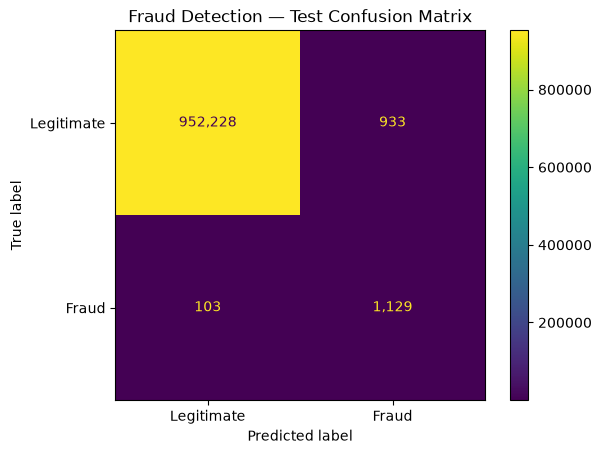

In [75]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=["Legitimate", "Fraud"],
    values_format=","
)

plt.title("Fraud Detection — Test Confusion Matrix")
plt.show()

In [77]:

import mlflow
import mlflow.sklearn

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
)
from mlflow.models import infer_signature


# --------------------------------------------------
# STEP 1: Connect to MLflow
# --------------------------------------------------
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("Fraud-Detection")


# --------------------------------------------------
# STEP 2: Combine the fitted preprocessor and model
# --------------------------------------------------
# preprocessor must already be fitted.
# best_model must already be trained on transformed data.

fraud_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", best_model),
    ]
)


# --------------------------------------------------
# STEP 3: Calculate validation predictions
# --------------------------------------------------
# X_val contains the ORIGINAL validation features,
# before preprocessing. Do not use X_val_tuning here.

y_val_prob = fraud_pipeline.predict_proba(X_val)[:, 1]

y_val_pred = (
    y_val_prob >= float(best_threshold)
).astype(int)


# --------------------------------------------------
# STEP 4: Calculate validation metrics
# --------------------------------------------------
precision = precision_score(
    y_val, y_val_pred, zero_division=0
)

recall = recall_score(
    y_val, y_val_pred, zero_division=0
)

f1 = f1_score(
    y_val, y_val_pred, zero_division=0
)

pr_auc = average_precision_score(
    y_val, y_val_prob
)

roc_auc = roc_auc_score(
    y_val, y_val_prob
)

tn, fp, fn, tp = confusion_matrix(
    y_val, y_val_pred, labels=[0, 1]
).ravel()


# --------------------------------------------------
# STEP 5: Log everything to MLflow
# --------------------------------------------------
with mlflow.start_run(run_name="XGBoost-Tuned"):

    # Log model parameters
    mlflow.log_params({
        "model_type": "XGBoost",
        "decision_threshold": float(best_threshold),
        "positive_class": 1,
    })

    # Log validation metrics
    mlflow.log_metrics({
        "validation_precision": float(precision),
        "validation_recall": float(recall),
        "validation_f1": float(f1),
        "validation_pr_auc": float(pr_auc),
        "validation_roc_auc": float(roc_auc),
        "validation_true_negatives": int(tn),
        "validation_false_positives": int(fp),
        "validation_false_negatives": int(fn),
        "validation_true_positives": int(tp),
    })

    # Create an example using the original input columns
    input_example = X_train_sample.head(5).copy()

    # Generate a signature for raw input -> prediction output
    example_predictions = fraud_pipeline.predict(input_example)

    signature = infer_signature(
        input_example,
        example_predictions
    )

    # Log the complete preprocessing + model pipeline
    mlflow.sklearn.log_model(
        sk_model=fraud_pipeline,
        name="fraud_detection_pipeline",
        signature=signature,
        input_example=input_example,
    )

    # Save additional information as tags
    mlflow.set_tag("project", "Fraud Detection")
    mlflow.set_tag("model_family", "XGBoost")
    mlflow.set_tag("evaluation_dataset", "validation")

    print("MLflow run completed successfully.")
    print("Run ID:", mlflow.active_run().info.run_id)


# --------------------------------------------------
# STEP 6: Display validation results
# --------------------------------------------------
print("\nValidation Results")
print("------------------")
print(f"Decision Threshold: {best_threshold:.4f}")
print(f"Precision:          {precision:.4f}")
print(f"Recall:             {recall:.4f}")
print(f"F1-Score:           {f1:.4f}")
print(f"PR-AUC:             {pr_auc:.4f}")
print(f"ROC-AUC:            {roc_auc:.4f}")

print("\nConfusion Matrix Counts")
print(f"True Negatives:  {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives:  {tp}")


c:\Users\Ritesh\anaconda3\envs\myenv\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


🏃 View run XGBoost-Tuned at: http://127.0.0.1:5000/#/experiments/1/runs/c12c5add70e444d7b9b3cb17465a1840
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


MlflowException: The saved sklearn model references untrusted types. If you are sure loading these types is safe, set the 'skops_trusted_types' parameter when calling 'log_model' or 'save_model' to the list of trusted types. Root error: Untrusted types found in the file: ['numpy.dtype', 'sklearn.compose._column_transformer._RemainderColsList', 'xgboost.core.Booster', 'xgboost.sklearn.XGBClassifier'].

In [78]:

import pandas as pd
from mlflow.models import infer_signature

# Use the original, untransformed input data
input_example = X_train_sample.head(5).copy()

# Convert integer columns to float where missing values
# may reasonably occur at inference time.
possible_missing_columns = input_example.select_dtypes(
    include=["integer"]
).columns

input_example[possible_missing_columns] = (
    input_example[possible_missing_columns].astype("float64")
)

# Generate predictions with the complete pipeline
example_predictions = fraud_pipeline.predict(input_example)

# Infer the model signature
signature = infer_signature(
    input_example,
    example_predictions
)

print("Input example shape:", input_example.shape)
print("Model signature generated successfully.")


Input example shape: (5, 7)
Model signature generated successfully.


In [79]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

# Replace these variable names with the actual names
# of your fitted models from Step 12.
candidate_models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Tuned XGBoost": best_model,
}

# Use the same transformed validation features that
# your candidate models were trained to accept.
X_eval = X_val_tuning

results = []

for name, model in candidate_models.items():

    probabilities = model.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(
            y_val, probabilities
        ),
        "ROC-AUC": roc_auc_score(
            y_val, probabilities
        ),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="PR-AUC",
    ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))

print("\nTop model by validation PR-AUC:")
print(comparison_df.iloc[0]["Model"])


NameError: name 'lr_model' is not defined

In [80]:

# Find model-related variables in your notebook
for name, obj in globals().copy().items():
    if hasattr(obj, "predict_proba"):
        print(name, "->", type(obj).__name__)


Pipeline -> ABCMeta
XGBClassifier -> type
xgb_model -> XGBClassifier
LogisticRegression -> type
baseline_model -> Pipeline
_20 -> Pipeline
DecisionTreeClassifier -> ABCMeta
RandomForestClassifier -> ABCMeta
model -> Pipeline
RandomizedSearchCV -> ABCMeta
xgb -> XGBClassifier
search -> RandomizedSearchCV
best_model -> XGBClassifier
_60 -> Pipeline
fraud_pipeline -> Pipeline


In [81]:

print("baseline_model:", baseline_model)
print("\nmodel:", model)
print("\nbest_model:", best_model)
print("\nfraud_pipeline:", fraud_pipeline)


baseline_model: Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['step', 'amount',
                                                   'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['type

In [82]:

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

# Store validation results
results = []

# Models that accept the original, unprocessed X_val
pipeline_models = {
    "Logistic Regression": baseline_model,
    "XGBoost Pipeline": model,
    "Tuned XGBoost Pipeline": fraud_pipeline,
}

for name, fitted_pipeline in pipeline_models.items():
    probabilities = fitted_pipeline.predict_proba(X_val)[:, 1]

    # Use 0.5 only for this initial comparison.
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "PR-AUC": average_precision_score(y_val, probabilities),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, predictions, zero_division=0
        ),
    })

# Compare the separately tuned XGBoost classifier
best_probabilities = best_model.predict_proba(X_val_tuning)[:, 1]
best_predictions = (best_probabilities >= 0.5).astype(int)

results.append({
    "Model": "Tuned XGBoost Classifier",
    "PR-AUC": average_precision_score(
        y_val, best_probabilities
    ),
    "ROC-AUC": roc_auc_score(
        y_val, best_probabilities
    ),
    "Precision": precision_score(
        y_val, best_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_val, best_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_val, best_predictions, zero_division=0
    ),
})

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    "PR-AUC", ascending=False
).reset_index(drop=True)

print(comparison_df.round(4).to_string(index=False))


                   Model  PR-AUC  ROC-AUC  Precision  Recall  F1-Score
Tuned XGBoost Classifier  0.9193   0.9974     0.7185  0.8847    0.7930
  Tuned XGBoost Pipeline  0.9193   0.9974     0.7185  0.8847    0.7930
        XGBoost Pipeline  0.9118   0.9970     0.5366  0.9172    0.6771
     Logistic Regression  0.6564   0.9935     0.0241  0.9700    0.0470


In [83]:

from pathlib import Path

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

print("Model folder created:", MODEL_DIR.resolve())


Model folder created: C:\Data Science\ML\ML Project\Project 2\generated\AI Projects store\fraud-detection-mlops\notebooks\models


In [84]:

import joblib

MODEL_PATH = MODEL_DIR / "fraud_detection_pipeline.joblib"

joblib.dump(fraud_pipeline, MODEL_PATH)

print("Production model saved successfully!")
print("Saved at:", MODEL_PATH.resolve())


Production model saved successfully!
Saved at: C:\Data Science\ML\ML Project\Project 2\generated\AI Projects store\fraud-detection-mlops\notebooks\models\fraud_detection_pipeline.joblib


In [85]:

import json

THRESHOLD_PATH = MODEL_DIR / "decision_threshold.json"

with open(THRESHOLD_PATH, "w") as file:
    json.dump(
        {"decision_threshold": float(best_threshold)},
        file,
        indent=4
    )

print("Decision threshold saved:", THRESHOLD_PATH.resolve())
print("Threshold:", best_threshold)


Decision threshold saved: C:\Data Science\ML\ML Project\Project 2\generated\AI Projects store\fraud-detection-mlops\notebooks\models\decision_threshold.json
Threshold: 0.2


In [86]:

import joblib
import json
import pandas as pd

# Reload the saved model
loaded_pipeline = joblib.load(MODEL_PATH)

# Reload the threshold
with open(THRESHOLD_PATH, "r") as file:
    saved_config = json.load(file)

loaded_threshold = saved_config["decision_threshold"]

# Predict using one original validation row
sample_transaction = X_val.iloc[[0]]

fraud_probability = loaded_pipeline.predict_proba(
    sample_transaction
)[0, 1]

fraud_prediction = (
    fraud_probability >= loaded_threshold
)

print("Fraud probability:", round(float(fraud_probability), 6))
print("Decision threshold:", loaded_threshold)
print("Prediction:", "FRAUD" if fraud_prediction else "NOT FRAUD")


Fraud probability: 1.2e-05
Decision threshold: 0.2
Prediction: NOT FRAUD


In [87]:
comparison_df.to_csv(
    "model_comparison_results.csv",
    index=False
)